In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data")
train = pd.read_csv(DATA / "train_test.csv", parse_dates=["date"])
val   = pd.read_csv(DATA / "validation.csv", parse_dates=["date"])
dec   = pd.read_csv(DATA / "december_chart_inputs.csv", parse_dates=["date"])

print(train.shape, val.shape, dec.shape)
train.head()

(48000, 14) (12000, 13) (31, 7)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [6]:
print("Missing in train:\n", train.isna().sum()[train.isna().sum() > 0])
print("\nMissing in validation:\n", val.isna().sum()[val.isna().sum() > 0])
train.describe().T.round(2)

Missing in train:
 weight          300
market_index    374
dtype: int64

Missing in validation:
 weight          165
market_index    249
dtype: int64


,count,mean,min,25%,50%,75%,max,std
pickup_lat,48000.0,35.647545,28.35765,31.98691,35.29479,39.41104,44.30296,4.315285
pickup_lon,48000.0,-90.928964,-121.69849,-98.40059,-88.08915,-83.28506,-69.5,13.482431
delivery_lat,48000.0,35.641175,28.35765,31.98691,35.29479,39.41104,44.30296,4.317199
delivery_lon,48000.0,-90.85731,-121.69849,-98.40059,-87.52871,-83.28506,-69.5,13.476589
distance,48000.0,1135.856654,70.0,550.4,953.3,1645.525,3439.8,728.564416
weight,47700.0,31028.844004,-47500.0,25800.0,31436.5,37018.0,47500.0,9391.44062
date,48000,2025-05-31 19:53:29.400000,2025-01-01 00:00:00,2025-03-18 00:00:00,2025-05-31 00:00:00,2025-08-15 00:00:00,2025-10-31 00:00:00,NaN
market_index,47626.0,1.083387,0.67639,0.94967,1.0558,1.21959,1.46778,0.168091
quote_signal,48000.0,2.062468,0.69228,1.89103,2.05575,2.221685,3.61035,0.291391
posted_rate,48000.0,2373.980682,57.22,1251.555,2030.76,3330.75,25533.0,1486.493245


In [7]:
print("Train dates:", train.date.min().date(), "->", train.date.max().date())
print("Val dates:  ", val.date.min().date(), "->", val.date.max().date())

new_cities = (set(val.pickup) | set(val.delivery)) - (set(train.pickup) | set(train.delivery))
print("Cities only in validation:", sorted(new_cities))
mask = val.pickup.isin(new_cities) | val.delivery.isin(new_cities)
print(f"Validation rows touching a new city: {mask.sum()} ({mask.mean():.1%})")

lane = (train.pickup == "Lexington") & (train.delivery == "Fort Wayne")
print("Lexington -> Fort Wayne loads in train:", lane.sum())

Train dates: 2025-01-01 -> 2025-10-31
Val dates:   2025-11-01 -> 2025-12-31
Cities only in validation: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation rows touching a new city: 1447 (12.1%)
Lexington -> Fort Wayne loads in train: 32


count    48000.00
mean         2.22
std          0.58
min          0.33
0.1%         0.44
1%           1.67
50%          2.15
99%          3.18
99.9%       10.07
max         14.13
Name: rpm, dtype: float64
rpm < 1.2: 335 | rpm > 5: 317
Negative weights - train: 292 val: 145
Weight exactly 47,500: 1191


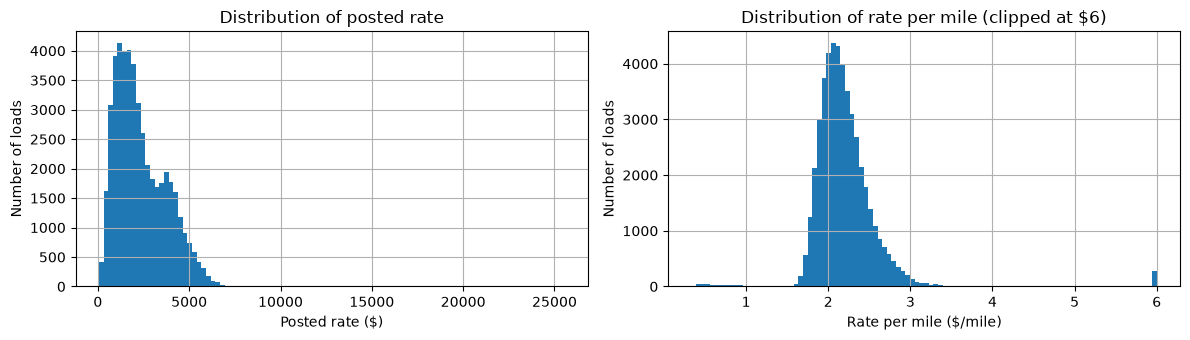

In [9]:
train["rpm"] = train.posted_rate / train.distance
print(train.rpm.describe(percentiles=[.001, .01, .5, .99, .999]).round(2))
print("rpm < 1.2:", (train.rpm < 1.2).sum(), "| rpm > 5:", (train.rpm > 5).sum())
print("Negative weights - train:", (train.weight < 0).sum(), "val:", (val.weight < 0).sum())
print("Weight exactly 47,500:", (train.weight == 47_500).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

train.posted_rate.hist(bins=100, ax=ax[0])
ax[0].set_title("Distribution of posted rate")
ax[0].set_xlabel("Posted rate ($)")
ax[0].set_ylabel("Number of loads")

train.rpm.clip(upper=6).hist(bins=100, ax=ax[1])
ax[1].set_title("Distribution of rate per mile (clipped at $6)")
ax[1].set_xlabel("Rate per mile ($/mile)")
ax[1].set_ylabel("Number of loads")

plt.tight_layout()
plt.show()

In [10]:
clean = train[(train.rpm > 1.2) & (train.rpm < 5)].copy()

print(clean.groupby("equipment").rpm.median().round(2), "\n")
clean["dist_bucket"] = pd.cut(clean.distance, [0, 250, 500, 1000, 1500, 2500, 3500])
print(clean.groupby("dist_bucket", observed=True).rpm.median().round(2), "\n")
print(clean[["distance", "weight", "market_index", "quote_signal", "rpm"]].corr().round(2)["rpm"])

equipment
Dry Van    2.05
Flatbed    2.22
Reefer     2.31
Name: rpm, dtype: float64 

dist_bucket
(0, 250]        2.74
(250, 500]      2.42
(500, 1000]     2.20
(1000, 1500]    2.07
(1500, 2500]    1.97
(2500, 3500]    1.87
Name: rpm, dtype: float64 

distance       -0.68
weight          0.15
market_index    0.17
quote_signal    0.10
rpm             1.00
Name: rpm, dtype: float64


Avg spread of market_index within one day: 0.025
date
Sunday       0.961
Monday       0.972
Saturday     1.021
Tuesday      1.046
Friday       1.108
Wednesday    1.127
Thursday     1.156
Name: market_index, dtype: float64


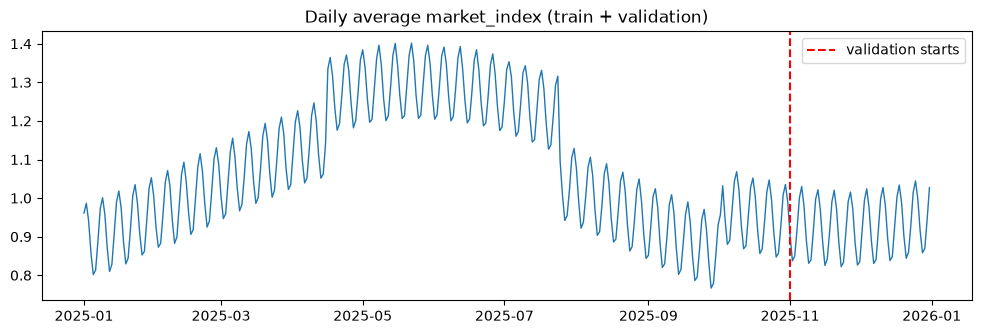

In [11]:
print("Avg spread of market_index within one day:",
      train.groupby("date").market_index.std().mean().round(3))

daily = pd.concat([train, val]).groupby("date").market_index.mean()
print(daily.groupby(daily.index.day_name()).mean().round(3).sort_values())

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily.index, daily.values, lw=1)
ax.axvline(pd.Timestamp("2025-11-01"), color="red", ls="--", label="validation starts")
ax.set_title("Daily average market_index (train + validation)")
ax.legend()
plt.show()